# R7 - Análisis complementario: ensamble de semillas

**Objetivo.** Evaluar, sobre validation y sin reentrenar, si promediar las probabilidades de las tres semillas (42, 43 y 44) de una misma configuración modifica el Average Precision (AP) frente a los modelos individuales, y comparar el ensamble de B2 con el de B0.

**Hipótesis (descriptiva, no confirmatoria).** El promedio de probabilidades de tres semillas reduce la dependencia de una semilla concreta (la reducción de variabilidad entre futuras ejecuciones del ensamble no se cuantifica directamente; ver limitaciones) y su AP no es inferior al AP medio de sus modelos individuales. No se presupone cuál de los dos ensambles obtiene mayor AP.

**Naturaleza del análisis.** Es un análisis **complementario**, no un experimento de optimización de B0-B3: no cambia la pérdida, los pesos, el entrenamiento ni el protocolo de selección de checkpoints, y no define una nueva configuración final.

| | Descripción |
|---|---|
| B0 | ConvNeXt-Tiny, representación A, entropía cruzada con pesos originales (α = 1.0) |
| B2 | ConvNeXt-Tiny, representación A, entropía cruzada con pesos atenuados (α = 0.5) |
| Ensamble B0 / B2 | Promedio aritmético simple de las probabilidades positivas de las semillas 42, 43 y 44 (sin ponderar ni optimizar pesos) |
| Ensamble B0+B2 (exploratorio) | Promedio simple de los seis modelos; solo informativo, no se selecciona como configuración final |

**Terminología.** Las 22 imágenes de `y_true = 1` son *positivas operacionales*: la etiqueta positiva agrupa las categorías originales 6 y 7, y la categoría 6 (cistoadenoma mucinoso) no es malignidad histológica.

**Restricciones.** No usa test, no entrena, no modifica B0, B2 ni sus predicciones, no optimiza umbrales (se usa el original, 0.5) ni pesos del ensamble. La selección de B2 ocurrió sobre este mismo validation, por lo que el análisis no es una evaluación independiente.

## 1. Configuración

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import average_precision_score, confusion_matrix, f1_score, precision_recall_curve, precision_score, roc_auc_score


def locate_project_root() -> Path:
    current_dir = Path.cwd().resolve()

    for candidate in [current_dir, *current_dir.parents]:
        if (candidate / "src").exists() and (candidate / "data").exists():
            return candidate

    raise FileNotFoundError("No se pudo localizar la raíz del proyecto.")


PROJECT_ROOT = locate_project_root()

SEEDS = [42, 43, 44]
THRESHOLD = 0.5  # umbral original: probabilidad >= 0.5 es positiva (igual que train.py)
N_BOOT = 2000
BOOT_SEED = 20260101  # semilla fija del remuestreo
CI_LEVEL = 95

CLASSIFICATION_DIR = PROJECT_ROOT / "results" / "classification"
R7_DIR = CLASSIFICATION_DIR / "r7_optimizacion"
CONFIG_DIRS = {
    "B0": CLASSIFICATION_DIR / "r4_benchmark" / "convnext_tiny" / "A",
    "B2": R7_DIR / "class_weights",
}
CONFIGS = list(CONFIG_DIRS)
SPLIT_CSV = PROJECT_ROOT / "configs" / "splits" / "mmotu_experimental_split.csv"
OUT_DIR = R7_DIR / "analisis_ensamble"  # salidas de este notebook; no toca B0-B3

# Resultados de una exploración previa (redondeados a 3 decimales): se contrastan, no se copian
REFERENCE = {"AP ensamble B0": 0.603, "AP ensamble B2": 0.632, "AP ensamble B0+B2": 0.642, "ROC-AUC ensamble B0+B2": 0.906}
REFERENCE_TOLERANCE = 0.0006  # medio punto del último decimal de la referencia, con margen

## 2. Integridad de los seis archivos

Cada archivo se indexa por `image_id` y se ordena por ese identificador, por lo que el análisis no depende del orden de filas. Se comprueba: columnas requeridas, ausencia de valores faltantes, probabilidades en [0, 1], `image_id` únicos, 200 imágenes, y coincidencia exacta del conjunto de `image_id` y de `y_true` entre los seis archivos y con la partición experimental (de donde se recupera `original_class`, solo para describir errores).

In [2]:
REQUIRED_COLUMNS = ["image_id", "y_true", "probability_malignant"]


def read_predictions(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)
    missing_columns = set(REQUIRED_COLUMNS) - set(df.columns)
    assert not missing_columns, f"{path}: faltan columnas {sorted(missing_columns)}"
    assert not df[REQUIRED_COLUMNS].isna().any().any(), f"{path}: valores faltantes"
    assert df["image_id"].is_unique, f"{path}: image_id repetidos"
    assert df["probability_malignant"].between(0, 1).all(), f"{path}: probabilidades fuera de [0, 1]"
    assert set(df["y_true"]) <= {0, 1}, f"{path}: y_true no binario"
    return df


RAW = {
    (config, seed): read_predictions(directory / f"seed_{seed}" / "val_predictions_best_auc.csv")
    for config, directory in CONFIG_DIRS.items()
    for seed in SEEDS
}
PRED = {key: df.set_index("image_id").sort_index() for key, df in RAW.items()}

split = pd.read_csv(SPLIT_CSV)
assert split["image_id"].is_unique
validation = split[split["experimental_split"] == "validation"].set_index("image_id").sort_index()

reference_frame = PRED[("B0", SEEDS[0])]
rows = []
for (config, seed), df in PRED.items():
    same_ids = df.index.equals(reference_frame.index)
    same_labels = same_ids and np.array_equal(df["y_true"].to_numpy(), reference_frame["y_true"].to_numpy())
    rows.append(
        {
            "config": config,
            "seed": seed,
            "n": len(df),
            "positivas operacionales": int(df["y_true"].sum()),
            "mismo conjunto de image_id": same_ids,
            "mismo y_true por image_id": same_labels,
            "mismo conjunto que la partición": df.index.equals(validation.index),
            "mismo orden de filas que B0/42": bool(np.array_equal(RAW[(config, seed)]["image_id"].to_numpy(), RAW[("B0", SEEDS[0])]["image_id"].to_numpy())),
        }
    )
integrity = pd.DataFrame(rows)
display(integrity)

assert len(PRED) == 6 and (integrity["n"] == 200).all()
assert integrity["mismo conjunto de image_id"].all() and integrity["mismo y_true por image_id"].all() and integrity["mismo conjunto que la partición"].all()
assert np.array_equal(reference_frame["y_true"].to_numpy(), validation["binary_label"].to_numpy())
print("Integridad correcta: 6 archivos con las mismas 200 imágenes (22 positivas operacionales y 178 negativas) y las mismas etiquetas.")

IMAGE_IDS = reference_frame.index.to_numpy()
y = reference_frame["y_true"].to_numpy()
ORIGINAL_CLASS = validation["original_class"].to_numpy()
INDIVIDUAL = {config: np.stack([PRED[(config, seed)]["probability_malignant"].to_numpy() for seed in SEEDS]) for config in CONFIGS}  # (semilla, imagen)

,config,seed,n,positivas operacionales,mismo conjunto de image_id,mismo y_true por image_id,mismo conjunto que la partición,mismo orden de filas que B0/42
0,B0,42,200,22,True,True,True,True
1,B0,43,200,22,True,True,True,True
2,B0,44,200,22,True,True,True,True
3,B2,42,200,22,True,True,True,True
4,B2,43,200,22,True,True,True,True
5,B2,44,200,22,True,True,True,True


Integridad correcta: 6 archivos con las mismas 200 imágenes (22 positivas operacionales y 178 negativas) y las mismas etiquetas.


## 3. Construcción de los ensambles

El ensamble promedia, imagen por imagen, las probabilidades positivas de los modelos, **con el mismo peso para cada uno** (no se ponderan semillas ni se ajusta nada sobre validation). El ensamble B0+B2 es exploratorio: promedia los seis modelos y no se considera una configuración final.

In [3]:
ENSEMBLES = {
    "Ensamble B0": INDIVIDUAL["B0"].mean(axis=0),
    "Ensamble B2": INDIVIDUAL["B2"].mean(axis=0),
    "Ensamble B0+B2 (exploratorio)": np.concatenate([INDIVIDUAL["B0"], INDIVIDUAL["B2"]]).mean(axis=0),
}
for name, prob in ENSEMBLES.items():
    assert prob.shape == (200,) and np.isfinite(prob).all() and 0 <= prob.min() and prob.max() <= 1, name
# Con igual número de modelos por configuración, el de seis equivale al promedio de los dos ensambles de tres
assert np.allclose(ENSEMBLES["Ensamble B0+B2 (exploratorio)"], (ENSEMBLES["Ensamble B0"] + ENSEMBLES["Ensamble B2"]) / 2)
print({name: prob.shape for name, prob in ENSEMBLES.items()})

{'Ensamble B0': (200,), 'Ensamble B2': (200,), 'Ensamble B0+B2 (exploratorio)': (200,)}


## 4. Métricas

AP y ROC-AUC no dependen del umbral. Sensibilidad, especificidad, precisión, F1 y matriz de confusión usan el umbral original de 0.5 (`probabilidad >= 0.5` es positiva), sin optimizarlo. La precisión y el F1 están definidos para la clase positiva; la precisión es 0 si no hay predicciones positivas. Se incluyen también los seis modelos individuales como referencia.

In [4]:
def metrics_for(prob):
    pred = (prob >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "ap": average_precision_score(y, prob),
        "roc_auc": roc_auc_score(y, prob),
        "sensibilidad": tp / (tp + fn),
        "especificidad": tn / (tn + fp),
        "precision": precision_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }


metric_rows = []
for config in CONFIGS:
    for i, seed in enumerate(SEEDS):
        metric_rows.append({"modelo": f"{config} semilla {seed}", "tipo": "individual", "config": config, **metrics_for(INDIVIDUAL[config][i])})
for name, prob in ENSEMBLES.items():
    metric_rows.append({"modelo": name, "tipo": "ensamble (exploratorio)" if "exploratorio" in name else "ensamble", "config": name.split()[1].split("(")[0], **metrics_for(prob)})
metrics = pd.DataFrame(metric_rows)

OUT_DIR.mkdir(parents=True, exist_ok=True)
metrics.round(4).to_csv(OUT_DIR / "metricas_ensamble.csv", index=False)
display(metrics.drop(columns=["tipo", "config"]).round(4))

# Contraste de los individuales con validation_metrics.json (el AP y el ROC-AUC de cada modelo no cambian)
for config in CONFIGS:
    for i, seed in enumerate(SEEDS):
        saved = json.loads((CONFIG_DIRS[config] / f"seed_{seed}" / "validation_metrics.json").read_text(encoding="utf-8"))
        mine = metrics_for(INDIVIDUAL[config][i])
        for key_mine, key_saved in [("ap", "average_precision"), ("roc_auc", "roc_auc"), ("sensibilidad", "recall_malignant"), ("especificidad", "specificity")]:
            assert abs(mine[key_mine] - saved[key_saved]) < 1e-8, (config, seed, key_mine)
print("Los seis modelos individuales reproducen AP, ROC-AUC, sensibilidad y especificidad de validation_metrics.json.")

,modelo,ap,roc_auc,sensibilidad,especificidad,precision,f1,tn,fp,fn,tp
0,B0 semilla 42,0.5898,0.8853,0.7727,0.7753,0.2982,0.4304,138,40,5,17
1,B0 semilla 43,0.5295,0.8292,0.3182,0.9775,0.6364,0.4242,174,4,15,7
2,B0 semilla 44,0.5046,0.8156,0.2727,0.9944,0.8571,0.4138,177,1,16,6
3,B2 semilla 42,0.6050,0.8639,0.5455,0.9326,0.5000,0.5217,166,12,10,12
4,B2 semilla 43,0.6501,0.8731,0.5000,0.9719,0.6875,0.5789,173,5,11,11
5,B2 semilla 44,0.5790,0.8233,0.3182,0.9888,0.7778,0.4516,176,2,15,7
6,Ensamble B0,0.6029,0.9014,0.3182,0.9719,0.5833,0.4118,173,5,15,7
7,Ensamble B2,0.6321,0.8693,0.4091,0.9831,0.7500,0.5294,175,3,13,9
8,Ensamble B0+B2 (exploratorio),0.6425,0.9060,0.4091,0.9719,0.6429,0.5000,173,5,13,9


Los seis modelos individuales reproducen AP, ROC-AUC, sensibilidad y especificidad de validation_metrics.json.


## 5. AP medio individual frente a AP del ensamble

El **promedio de los AP individuales no es el AP de las probabilidades promediadas**: el AP es una función no lineal de la ordenación de las imágenes, de modo que promediar probabilidades produce una nueva ordenación cuyo AP no es la media de los tres. Por eso se comparan las dos cantidades, sin esperar que coincidan.

In [5]:
individual_ap = {config: np.array([average_precision_score(y, INDIVIDUAL[config][i]) for i in range(len(SEEDS))]) for config in CONFIGS}
ensemble_ap = {config: average_precision_score(y, ENSEMBLES[f"Ensamble {config}"]) for config in CONFIGS}

comparison = pd.DataFrame(
    [
        {
            "config": config,
            "AP semilla 42": individual_ap[config][0],
            "AP semilla 43": individual_ap[config][1],
            "AP semilla 44": individual_ap[config][2],
            "AP medio individual": individual_ap[config].mean(),
            "DE entre semillas (n-1)": individual_ap[config].std(ddof=1),
            "AP del ensamble": ensemble_ap[config],
            "ensamble - medio individual": ensemble_ap[config] - individual_ap[config].mean(),
            "ensamble - mejor individual": ensemble_ap[config] - individual_ap[config].max(),
        }
        for config in CONFIGS
    ]
)
comparison.round(4).to_csv(OUT_DIR / "ap_individual_vs_ensamble.csv", index=False)
display(comparison.round(4))

,config,AP semilla 42,AP semilla 43,AP semilla 44,AP medio individual,DE entre semillas (n-1),AP del ensamble,ensamble - medio individual,ensamble - mejor individual
0,B0,0.5898,0.5295,0.5046,0.5413,0.0438,0.6029,0.0616,0.0132
1,B2,0.6050,0.6501,0.5790,0.6114,0.0359,0.6321,0.0208,-0.0179


## 6. Ensamble B2 frente a ensamble B0: ΔAP con bootstrap pareado

Procedimiento, con semilla fija (`BOOT_SEED`) y `N_BOOT = 2000` réplicas:

- En cada réplica se remuestrean con reemplazo las imágenes **dentro de cada clase** (22 positivas operacionales y 178 negativas).
- **Los mismos índices se aplican a ambos ensambles** (y al ensamble exploratorio): pareado por imagen.
- Se calcula el AP de cada ensamble en la réplica y el ΔAP = AP(ensamble B2) − AP(ensamble B0). El IC del 95 % es el percentil 2.5-97.5 de esos ΔAP.

El intervalo mide la incertidumbre por **qué imágenes** componen validation, con los modelos entrenados fijos. **No es una prueba confirmatoria independiente**: los checkpoints y B2 se seleccionaron sobre este mismo validation. Además, las tres predicciones de una misma imagen en un ensamble proceden del mismo conjunto de imágenes y **no son observaciones estadísticamente independientes**; tampoco hay identificadores de paciente.

In [6]:
rng = np.random.default_rng(BOOT_SEED)
positives = np.flatnonzero(y == 1)
negatives = np.flatnonzero(y == 0)
names = list(ENSEMBLES)

boot_ap = np.empty((N_BOOT, len(names)))
for b in range(N_BOOT):
    idx = np.concatenate([rng.choice(positives, positives.size), rng.choice(negatives, negatives.size)])
    yb = y[idx]
    for j, name in enumerate(names):
        boot_ap[b, j] = average_precision_score(yb, ENSEMBLES[name][idx])
assert np.isfinite(boot_ap).all()

lo, hi = (100 - CI_LEVEL) / 2, 100 - (100 - CI_LEVEL) / 2
j0, j2, j6 = (names.index(n) for n in ("Ensamble B0", "Ensamble B2", "Ensamble B0+B2 (exploratorio)"))
boot_delta = boot_ap[:, j2] - boot_ap[:, j0]
delta_observed = ensemble_ap["B2"] - ensemble_ap["B0"]
delta_low, delta_high = np.percentile(boot_delta, [lo, hi])

ap_ci = pd.DataFrame(
    {
        "AP observado": [average_precision_score(y, ENSEMBLES[n]) for n in names],
        f"IC{CI_LEVEL}% inf": np.percentile(boot_ap, lo, axis=0),
        f"IC{CI_LEVEL}% sup": np.percentile(boot_ap, hi, axis=0),
        "EE bootstrap": boot_ap.std(axis=0, ddof=1),
    },
    index=names,
)
display(ap_ci.round(4))

delta_table = pd.DataFrame(
    [
        {
            "comparación": "Ensamble B2 - Ensamble B0",
            "ΔAP observado": delta_observed,
            "media bootstrap": boot_delta.mean(),
            "EE bootstrap": boot_delta.std(ddof=1),
            f"IC{CI_LEVEL}% inf": delta_low,
            f"IC{CI_LEVEL}% sup": delta_high,
            "réplicas con ΔAP > 0": (boot_delta > 0).mean(),
            "n_boot": N_BOOT,
            "boot_seed": BOOT_SEED,
        }
    ]
)
display(delta_table.round(4))

ap_ci.round(4).rename_axis("ensamble").reset_index().to_csv(OUT_DIR / "ap_ensambles_ic_bootstrap.csv", index=False)
delta_table.round(4).to_csv(OUT_DIR / "delta_ap_ensamble_b2_vs_b0.csv", index=False)

,AP observado,IC95% inf,IC95% sup,EE bootstrap
Ensamble B0,0.6029,0.4410,0.7652,0.0861
Ensamble B2,0.6321,0.4607,0.8069,0.0890
Ensamble B0+B2 (exploratorio),0.6425,0.4777,0.8102,0.0850


,comparación,ΔAP observado,media bootstrap,EE bootstrap,IC95% inf,IC95% sup,réplicas con ΔAP > 0,n_boot,boot_seed
0,Ensamble B2 - Ensamble B0,0.0292,0.0286,0.0481,-0.0609,0.1266,0.726,2000,20260101


## 7. Errores al umbral 0.5: falsos positivos y falsos negativos

Descripción de los errores de los ensambles, sin atribuir causas. Se indica cuántos errores comparten ambos ensambles y cómo se reparten por categoría original (solo descriptivo: cada imagen cuenta una vez; las tres predicciones de un ensamble sobre una misma imagen no son observaciones independientes).

In [7]:
pred_labels = {name: (prob >= THRESHOLD).astype(int) for name, prob in ENSEMBLES.items()}
is_fn = {name: (y == 1) & (pred == 0) for name, pred in pred_labels.items()}
is_fp = {name: (y == 0) & (pred == 1) for name, pred in pred_labels.items()}

error_rows = []
for name in ENSEMBLES:
    error_rows.append(
        {
            "ensamble": name,
            "falsos positivos (de 178 negativas)": int(is_fp[name].sum()),
            "falsos negativos (de 22 positivas)": int(is_fn[name].sum()),
            "FN categoría 6 (de 15)": int((is_fn[name] & (ORIGINAL_CLASS == 6)).sum()),
            "FN categoría 7 (de 7)": int((is_fn[name] & (ORIGINAL_CLASS == 7)).sum()),
        }
    )
errors = pd.DataFrame(error_rows)
display(errors)

overlap = []
for kind, flags in (("falsos positivos", is_fp), ("falsos negativos", is_fn)):
    a, b = flags["Ensamble B0"], flags["Ensamble B2"]
    overlap.append({"tipo de error": kind, "solo ensamble B0": int((a & ~b).sum()), "en ambos": int((a & b).sum()), "solo ensamble B2": int((b & ~a).sum())})
overlap = pd.DataFrame(overlap)
display(overlap)

fp_by_class = pd.DataFrame(
    {name: pd.Series(ORIGINAL_CLASS[is_fp[name]]).value_counts().reindex(range(6), fill_value=0) for name in ("Ensamble B0", "Ensamble B2")}
).rename_axis("categoría original (0-5)")
display(fp_by_class.T)

errors.to_csv(OUT_DIR / "errores_ensamble.csv", index=False)
overlap.to_csv(OUT_DIR / "errores_ensamble_solapamiento.csv", index=False)

,ensamble,falsos positivos (de 178 negativas),falsos negativos (de 22 positivas),FN categoría 6 (de 15),FN categoría 7 (de 7)
0,Ensamble B0,5,15,11,4
1,Ensamble B2,3,13,9,4
2,Ensamble B0+B2 (exploratorio),5,13,9,4


,tipo de error,solo ensamble B0,en ambos,solo ensamble B2
0,falsos positivos,2,3,0
1,falsos negativos,2,13,0


categoría original (0-5),0,1,2,3,4,5
Ensamble B0,1,1,1,1,1,0
Ensamble B2,0,1,1,1,0,0


## 8. Costo computacional

El ensamble **no reduce** el costo: lo multiplica por el número de modelos. Se distingue lo que se puede contar de lo que no se midió.

- **Inferencias por imagen** (pasadas hacia adelante de la red): 1 en un modelo individual, 3 en el ensamble de una configuración y 6 en el ensamble B0+B2 exploratorio. En validation: 200, 600 y 1200 inferencias, respectivamente.
- **Modelos a conservar y cargar:** 1, 3 y 6 checkpoints, respectivamente.
- **Entrenamiento:** el ensamble reutiliza las tres corridas ya hechas de cada configuración; no requiere entrenar nada nuevo para este análisis.
- **Latencia y memoria: no se midieron.** Dependen del hardware, del tamaño de lote y de si los modelos se ejecutan en serie o en paralelo; este notebook no cronometra ni mide memoria y no se estiman aquí. Que el número de inferencias se triplique no implica que la latencia se triplique.

## 9. Predicciones consolidadas y figuras

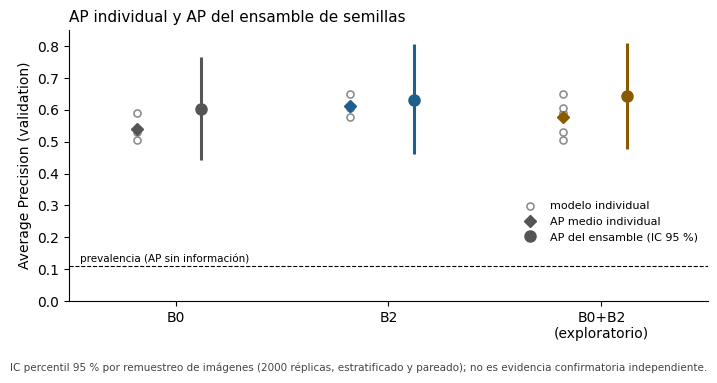

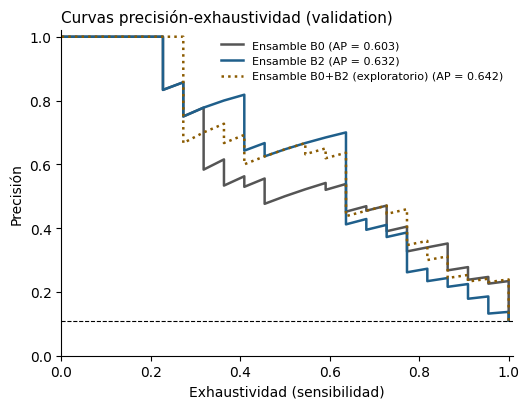

In [8]:
consolidated = pd.DataFrame({"image_id": IMAGE_IDS, "y_true": y, "original_class": ORIGINAL_CLASS})
for config in CONFIGS:
    for i, seed in enumerate(SEEDS):
        consolidated[f"prob_{config}_seed{seed}"] = INDIVIDUAL[config][i]
consolidated["prob_ensamble_B0"] = ENSEMBLES["Ensamble B0"]
consolidated["prob_ensamble_B2"] = ENSEMBLES["Ensamble B2"]
consolidated["prob_ensamble_B0_B2_exploratorio"] = ENSEMBLES["Ensamble B0+B2 (exploratorio)"]
consolidated["pred_ensamble_B0"] = pred_labels["Ensamble B0"]
consolidated["pred_ensamble_B2"] = pred_labels["Ensamble B2"]
consolidated["pred_ensamble_B0_B2_exploratorio"] = pred_labels["Ensamble B0+B2 (exploratorio)"]
assert consolidated["image_id"].is_unique and len(consolidated) == 200
consolidated.to_csv(OUT_DIR / "predicciones_consolidadas.csv", index=False, float_format="%.10g")

colors = {"B0": "#555555", "B2": "#1f5f8b", "mix": "#8a5a00"}

# Figura 1: AP individual (por semilla) y AP del ensamble con su IC bootstrap
fig, ax = plt.subplots(figsize=(7.2, 3.8))
groups = [("B0", "B0", colors["B0"]), ("B2", "B2", colors["B2"]), ("B0+B2", "mix", colors["mix"])]
for x_pos, (label, key, color) in enumerate(groups):
    if key == "mix":
        ens_name = "Ensamble B0+B2 (exploratorio)"
        individual = np.concatenate([individual_ap["B0"], individual_ap["B2"]])
    else:
        ens_name = f"Ensamble {key}"
        individual = individual_ap[key]
    j = names.index(ens_name)
    ax.scatter(np.full(individual.size, x_pos - 0.18), individual, s=26, facecolors="white", edgecolors="#888888", lw=1.1, zorder=3, label="modelo individual" if x_pos == 0 else None)
    ax.plot(x_pos - 0.18, individual.mean(), "D", color=color, ms=6, zorder=4, label="AP medio individual" if x_pos == 0 else None)
    ax.plot([x_pos + 0.12] * 2, [ap_ci[f"IC{CI_LEVEL}% inf"].iloc[j], ap_ci[f"IC{CI_LEVEL}% sup"].iloc[j]], color=color, lw=2.2, solid_capstyle="butt", zorder=2)
    ax.plot(x_pos + 0.12, ap_ci["AP observado"].iloc[j], "o", color=color, ms=8, zorder=4, label="AP del ensamble (IC 95 %)" if x_pos == 0 else None)
ax.axhline(22 / 200, color="black", lw=0.8, ls="--")
ax.annotate("prevalencia (AP sin información)", (-0.45, 22 / 200), xytext=(0, 3), textcoords="offset points", fontsize=7.5)
ax.set_xticks(range(3))
ax.set_xticklabels(["B0", "B2", "B0+B2\n(exploratorio)"])
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(0, 0.85)
ax.set_ylabel("Average Precision (validation)")
ax.set_title("AP individual y AP del ensamble de semillas", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8, loc="lower right", bbox_to_anchor=(1.0, 0.18))
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.text(0.01, 0.005, f"IC percentil {CI_LEVEL} % por remuestreo de imágenes ({N_BOOT} réplicas, estratificado y pareado); no es evidencia confirmatoria independiente.", fontsize=7.5, color="#444444", va="bottom")
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(OUT_DIR / "ap_individual_vs_ensamble.png", dpi=200)
plt.show()

# Figura 2: curvas precisión-exhaustividad de los ensambles
fig, ax = plt.subplots(figsize=(5.4, 4.2))
for name, color, style in [("Ensamble B0", colors["B0"], "-"), ("Ensamble B2", colors["B2"], "-"), ("Ensamble B0+B2 (exploratorio)", colors["mix"], ":")]:
    precision, recall, _ = precision_recall_curve(y, ENSEMBLES[name])
    ax.plot(recall, precision, style, color=color, lw=1.8, label=f"{name} (AP = {average_precision_score(y, ENSEMBLES[name]):.3f})")
ax.axhline(22 / 200, color="black", lw=0.8, ls="--")
ax.set_xlabel("Exhaustividad (sensibilidad)")
ax.set_ylabel("Precisión")
ax.set_xlim(0, 1.01)
ax.set_ylim(0, 1.02)
ax.set_title("Curvas precisión-exhaustividad (validation)", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8, loc="upper right")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "curvas_pr_ensambles.png", dpi=200)
plt.show()

## 10. Contraste con los resultados exploratorios anteriores

Los valores de una exploración previa (redondeados a 3 decimales) se contrastan, no se copian, con una tolerancia de medio punto del último decimal más un margen.

In [9]:
computed = {
    "AP ensamble B0": ensemble_ap["B0"],
    "AP ensamble B2": ensemble_ap["B2"],
    "AP ensamble B0+B2": average_precision_score(y, ENSEMBLES["Ensamble B0+B2 (exploratorio)"]),
    "ROC-AUC ensamble B0+B2": roc_auc_score(y, ENSEMBLES["Ensamble B0+B2 (exploratorio)"]),
}
contrast = pd.DataFrame({"referencia exploratoria": REFERENCE, "calculado": computed})
contrast["diferencia"] = contrast["calculado"] - contrast["referencia exploratoria"]
contrast["dentro de la tolerancia"] = contrast["diferencia"].abs() <= REFERENCE_TOLERANCE
display(contrast.round(4))
assert contrast["dentro de la tolerancia"].all(), "Alguna métrica queda fuera de la tolerancia respecto de la exploración previa"
print(f"Las cuatro métricas coinciden con la exploración previa (tolerancia {REFERENCE_TOLERANCE}).")

,referencia exploratoria,calculado,diferencia,dentro de la tolerancia
AP ensamble B0,0.603,0.6029,-0.0001,True
AP ensamble B2,0.632,0.6321,0.0001,True
AP ensamble B0+B2,0.642,0.6425,0.0005,True
ROC-AUC ensamble B0+B2,0.906,0.9060,0.0000,True


Las cuatro métricas coinciden con la exploración previa (tolerancia 0.0006).


## 11. Limitaciones

- **Validation ya se usó para seleccionar.** Los checkpoints se eligieron por `val_roc_auc` en validation y B2 se conservó tras compararse allí con B1 y B3. Estos resultados no son una evaluación independiente y el IC bootstrap no es una prueba confirmatoria ni corrige esa selección; el sesgo probable es favorable a B2.
- **Solo 22 positivas operacionales** (categorías 6 y 7 agrupadas): el AP depende de la ordenación de unas pocas imágenes, y cada falso negativo equivale a 4.5 puntos de sensibilidad.
- **Las tres predicciones de una imagen no son independientes.** El ensamble promedia tres modelos evaluados sobre las mismas imágenes; el bootstrap remuestrea imágenes, no modelos, y está condicionado a las tres semillas entrenadas. La variabilidad de entrenamiento solo se aprecia en la dispersión entre las tres semillas. No hay identificadores de paciente.
- **El ensamble no cuantifica la variabilidad entre ejecuciones futuras.** Promediar las probabilidades de tres semillas genera una única predicción consolidada por imagen, pero con un solo conjunto de tres semillas no permite cuantificar directamente la reducción de variabilidad entre futuras ejecuciones del ensamble: la dispersión entre las tres semillas individuales es la única referencia de variabilidad de entrenamiento disponible, y el bootstrap no la evalúa. La hipótesis sobre la variabilidad es, por tanto, descriptiva.
- **Sin optimización.** No se ajustan umbral ni pesos del ensamble sobre validation; los valores de sensibilidad, especificidad, precisión y F1 corresponden al umbral original 0.5. Son comparables de forma descriptiva entre configuraciones porque se calculan sobre las mismas imágenes, etiquetas y umbral; pero las diferencias en las distribuciones de probabilidades (por ejemplo, por los pesos distintos de B0 y B2 o por el promedio entre semillas) pueden hacer que el umbral 0.5 corresponda a puntos operativos distintos, de modo que las diferencias no deben leerse como diferencias de calidad en un mismo punto operativo.
- **Ensamble de seis modelos exploratorio.** No es una configuración candidata ni se selecciona; mezcla dos configuraciones de entrenamiento distintas y no tiene un diseño propio.
- **Costo.** Triplica (o sextuplica) las inferencias; no se midió latencia ni memoria.
- **No es un experimento B0-B3.** No cambia el entrenamiento ni modifica los resultados de B0-B3.

## 12. Conclusión

**Hechos (validation, umbral 0.5 para sensibilidad, especificidad, precisión y F1).**

- El AP del ensamble de tres semillas es 0.6029 en B0 y 0.6321 en B2; el ensamble exploratorio de seis modelos obtiene 0.6425 (ROC-AUC 0.9060). Frente al AP medio de sus modelos individuales (0.5413 y 0.6114), el ensamble es +0.0616 mayor en B0 y +0.0208 en B2. En B0 supera incluso al mejor modelo individual (0.5898); en B2 queda por debajo del mejor individual (0.6501). El AP del ensamble no es el promedio de los AP individuales.
- ΔAP entre ensambles (B2 − B0): +0.0292, IC 95 % bootstrap [−0.0609, +0.1266], con 72.6 % de réplicas con ΔAP > 0 (descriptivo). Para los modelos individuales, el ΔAP medio del notebook 04 era +0.0701 con IC [+0.0044, +0.1387]. El ROC-AUC del ensamble B2 (0.8693) es menor que el del ensamble B0 (0.9014).
- Con el umbral 0.5, el ensamble B0 comete 5 falsos positivos y 15 falsos negativos, y el ensamble B2, 3 y 13. Todos los errores del ensamble B2 son también errores del ensamble B0 (3 de los 5 falsos positivos y 13 de los 15 falsos negativos).
- El ensamble exige tres inferencias por imagen (seis en el exploratorio) frente a una. No se midieron latencia ni memoria.

**Interpretación (provisional).** Promediar las semillas aumenta el AP respecto de la media individual, sobre todo en B0, y la ventaja de B2 sobre B0 se reduce al compararse como ensambles; con este análisis no se separa si el motivo es la reducción de variabilidad entre semillas u otro. El intervalo del ΔAP entre ensambles incluye el cero, por lo que no se distingue la diferencia de la variabilidad por muestreo de imágenes; que lo haga para los individuales no se transfiere a los ensambles. No se atribuyen causas a los errores restantes.

**Alcance.** Es un análisis complementario sobre validation, no un experimento de optimización: no modifica B0-B3, no selecciona ninguna configuración final y el ensamble B0+B2 es solo exploratorio. Los intervalos están condicionados a la selección previa sobre este mismo validation y a tres semillas entrenadas, y las tres predicciones de cada imagen no son observaciones independientes; no constituyen evidencia confirmatoria.